#### Further analysis of the three-chamber system with multiple potential outputs

Three-chamber system in a "V" layout

Run simulations in parallel using parallel_V_formation.py`, which then saves to disk as `fine_output.npz`. Analysis proceeds after loading in the npz.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import scipy
import scipy.stats

import cnetwork
from cnetwork import MagmaChamber, GlobalSystemThreshold

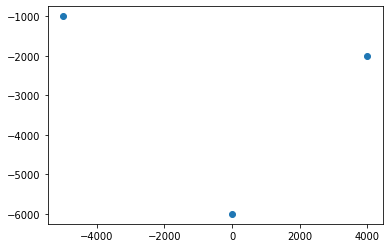

In [2]:
# Set reference density of melt
rhoref = 2500
# Set limits of characteristic size of chamber
R_ref = 1000
# Uniformly randomly distribution volume
V_ref = (4/3)*np.pi*R_ref**3

# Generate list of chambers
x_nodes = np.array([0,     -5000,  4000,])
y_nodes = np.array([0,     -0,     0,])
z_nodes = np.array([-6000, -1000,  -2000,])
V_nodes = np.array([4.0,    0.25,  1 ]) * V_ref
list_nodes = [MagmaChamber(x=x, y=y, z=z,
  p_setting=None, vref=1.0/rhoref,
  T_setting=1000+273.15, V_setting=V)
  for (x,y,z,V) in zip(x_nodes, y_nodes, z_nodes, V_nodes)]
plt.scatter(x_nodes, z_nodes)

In [ ]:
import parallel_V_formation
parallel_V_formation.run_parallel()

### Sample parameter space in parallel

In [ ]:
_params = [(mg_contrast.ravel()[i],
            mg_rates.ravel()[i],
            i) for i, _ in enumerate(mg_rates.ravel())]

with mp.Pool() as pool:
  outs = pool.starmap(run_simulation, _params)
  
# Restack outputs as n-d arrays of shape (n_contrast_cases, n_rate_cases, n_time, n_chambers)
_m_eruption_by_chamber, _m, _p, _u = zip(*outs)

export_m_eruption_by_chamber = np.reshape(np.stack(_m_eruption_by_chamber, axis=0),
          (*outputs.shape, *_m_eruption_by_chamber[0].shape))
export_m = np.reshape(np.stack(_m, axis=0),
          (*outputs.shape, *_m[0].shape))
export_p = np.reshape(np.stack(_p, axis=0),
          (*outputs.shape, *_p[0].shape))
export_u = np.reshape(np.stack(_u, axis=0),
          (*outputs.shape, *_u[0].shape))
np.savez_compressed("fine_output_2.npz",
                    m_eruption_by_chamber=export_m_eruption_by_chamber,
                    m=export_m,
                    p=export_p,
                    # u=export_u,
                    mg_rates=mg_rates,
                    mg_contrast=mg_contrast,
                    t_vec=t_vec,
                    )

In [ ]:
run_simulation(eruptibility_contrast, turnover_rate, ij)

In [4]:
# Load to memory
blob = np.load("fine_output.npz")
m_eruption_by_chamber = blob["m_eruption_by_chamber"]
# m = blob["m"]
p = blob["p"]
# u = blob["u"]
mg_rates = blob["mg_rates"]
mg_contrast = blob["mg_contrast"]
# Static t_vec for fine_output.npz
t_vec = np.linspace(0, 100e7, 400000)

FileNotFoundError: [Errno 2] No such file or directory: 'fine_output.npz'

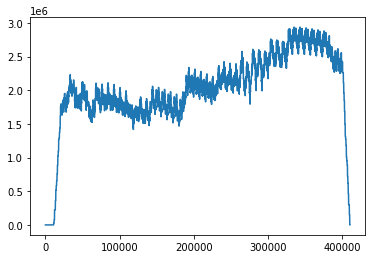

In [ ]:
plt.plot(np.convolve(m_eruption_by_chamber[10,49,:,1], np.ones((10000,))))

In [ ]:
# Compute dependent quantities
dt = (t_vec[1] - t_vec[0])
t_total = (t_vec[-1] - t_vec[0])
max_rates = mg_rates * V_ref * rhoref
# Time-integration of eruption rates
m_eruption_integrated = dt * np.einsum(
  "ijkl -> ijl", m_eruption_by_chamber)
# Compute partition of erupted material with shape (*, *, nchambers)
eruption_partition = m_eruption_integrated / np.sum(
  m_eruption_integrated, axis=2, keepdims=True)
# Compute throughput
#   (maps to intrusive*-extrusive (* of injected mass))
throughput_efficiency = m_eruption_integrated.sum(axis=2) / (t_total * max_rates)

In [ ]:
mg_rates.shape
m_eruption_by_chamber[:,:,...].shape

(12, 50, 400000, 3)

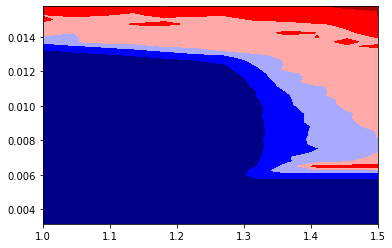

In [ ]:

plt.contourf(mg_contrast, (mg_rates) * 3.1536e+7, m_eruption_by_chamber[:,:,:,1].sum(axis=-1),
  cmap=matplotlib.pyplot.cm.seismic)

Plots of eruption rates by chamber: 


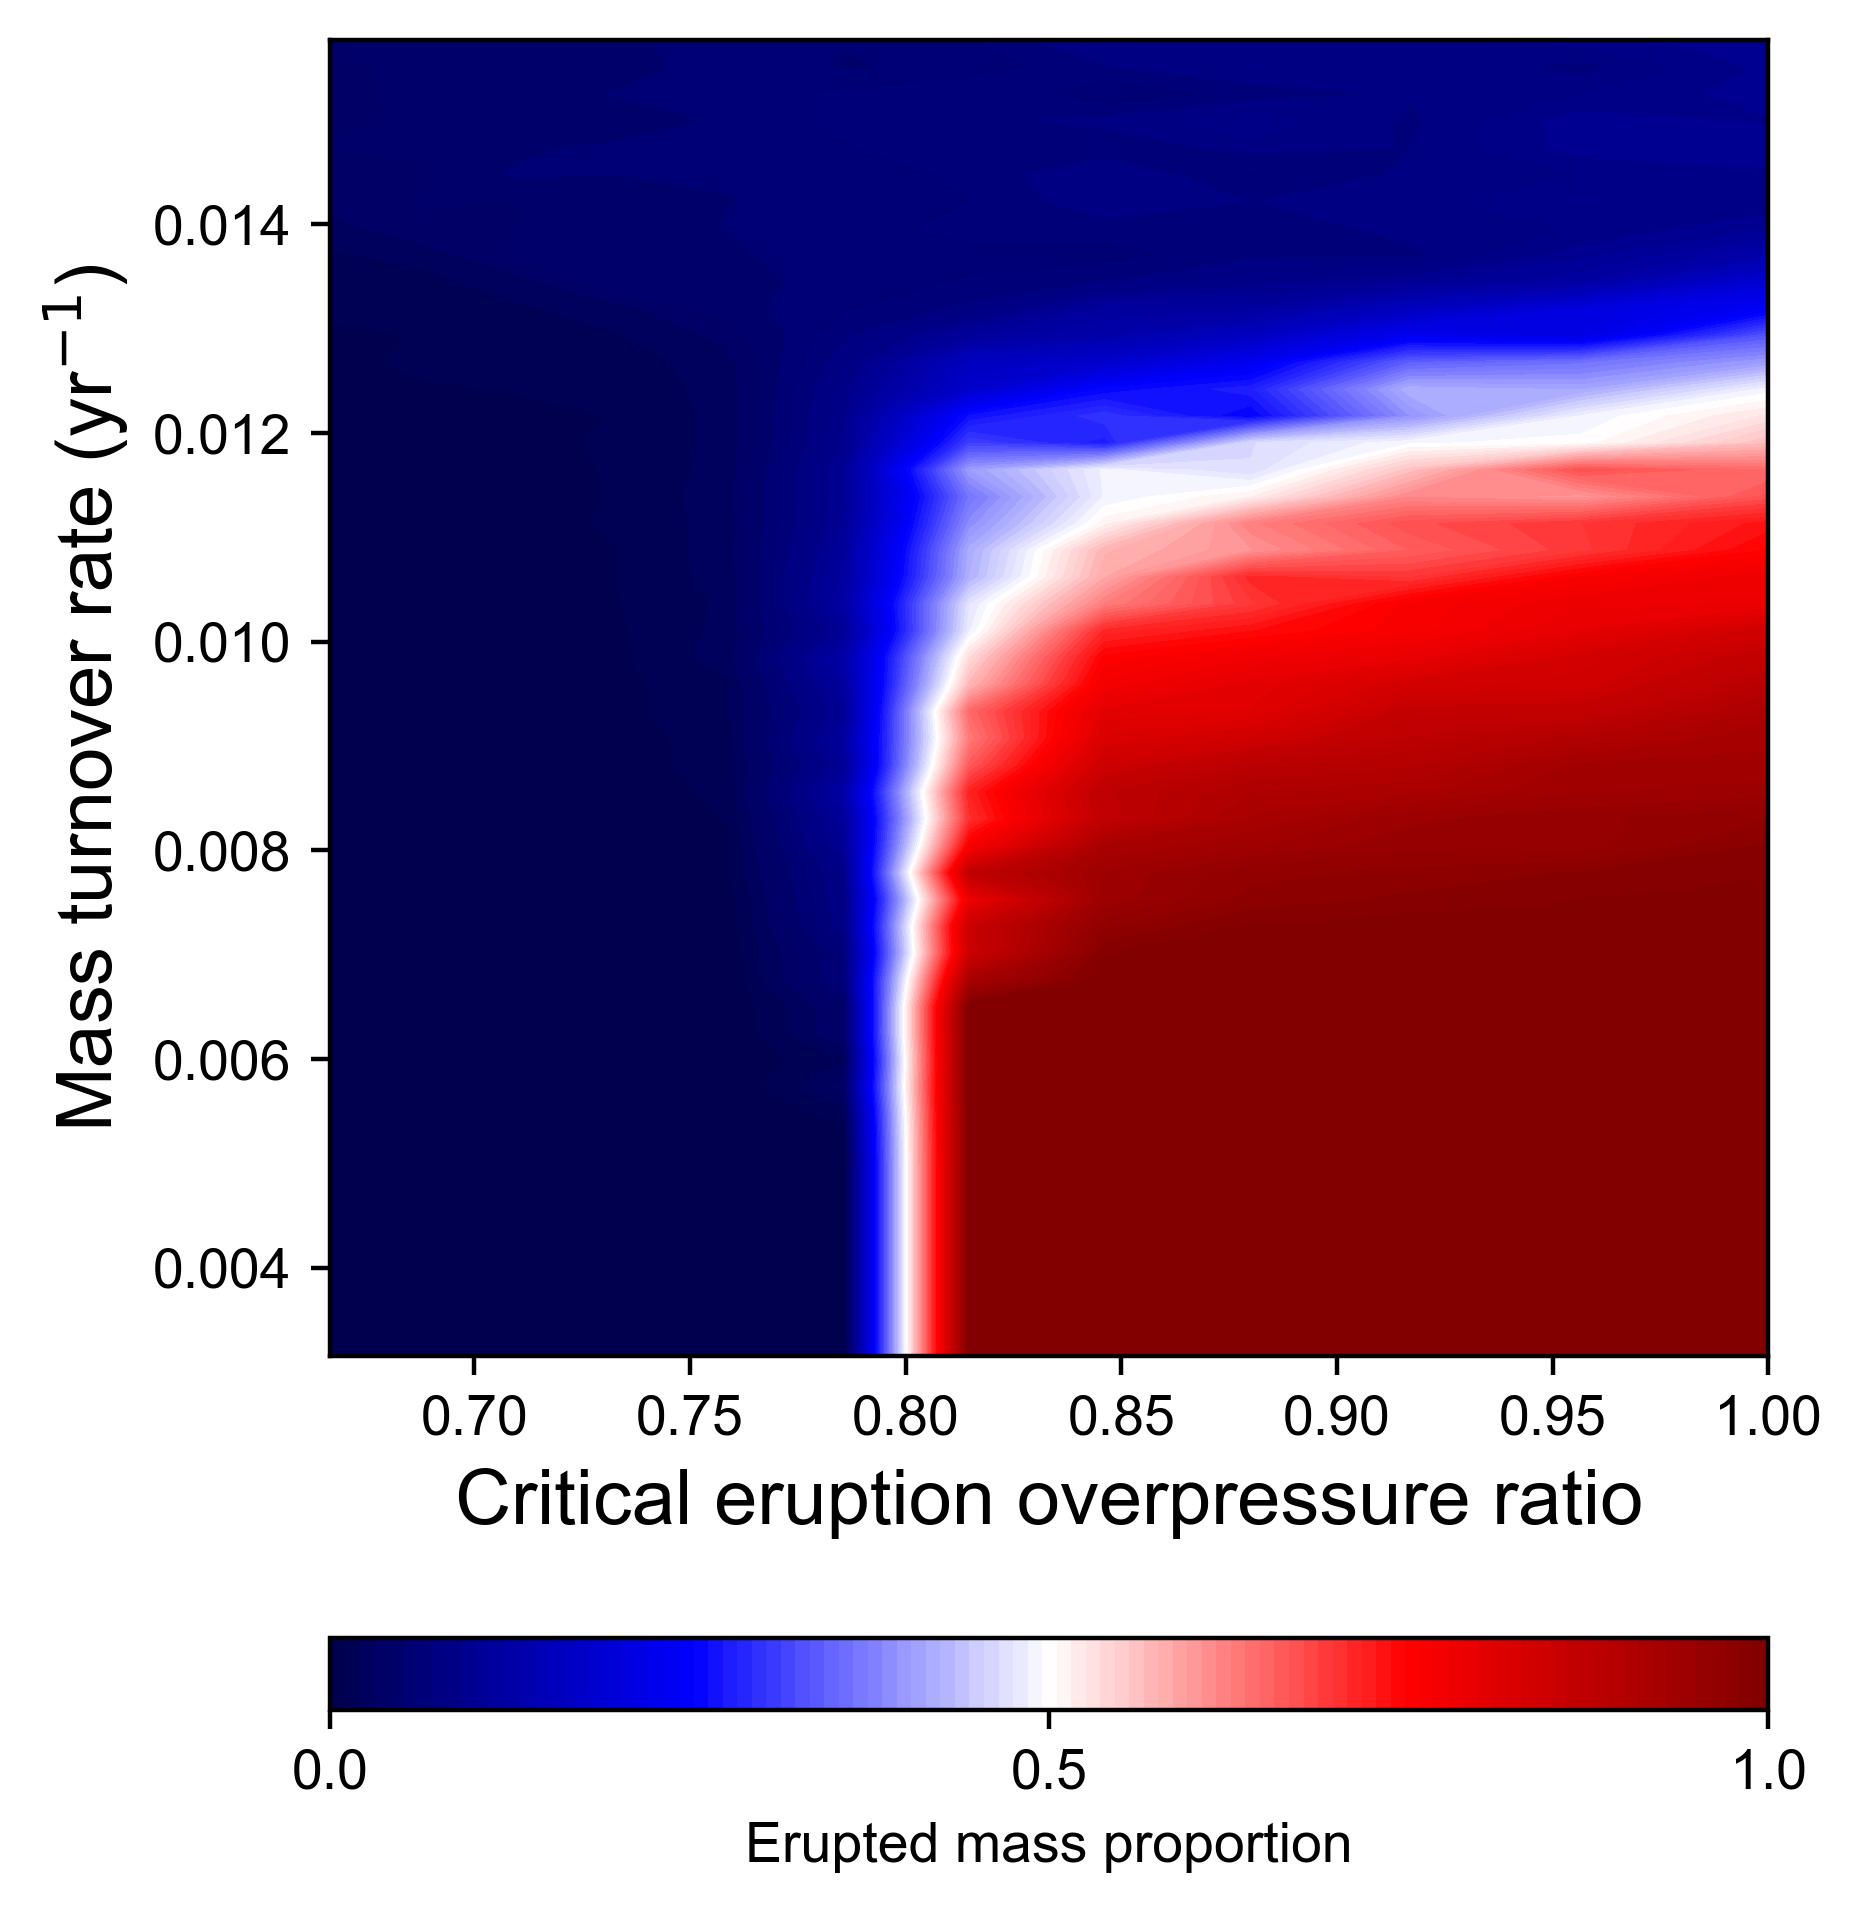

In [ ]:

plt.rcParams["font.family"] = "sans-serif" # default
plt.rcParams["font.family"] = "arial" # default


plt.subplots(figsize=(8.5,5), dpi=400)
plt.subplot(1,2,1)
# Plot indicator for eruption from chamber #1 (when eruption_partition[:, :, 1]
# is zero, only chamber #2 erupts)
plt.contourf(1/mg_contrast, (mg_rates) * 3.1536e+7, 1 - eruption_partition[:,:,1],
  levels=np.linspace(0, 1, 100), cmap=matplotlib.pyplot.cm.seismic)
plt.xlabel("Critical eruption overpressure ratio", fontsize=14)
# plt.ylabel("Mass turnover rate: lowest node (1/s)")
plt.ylabel("Mass turnover rate (yr${}^{-1}$)", fontsize=14)
cb = plt.colorbar(label="Erupted mass proportion", location="bottom",
             ticks=[0, 0.5, 1.0])

# plt.subplot(1,2,2)
# plt.contourf(mg_contrast, mg_rates, throughput_efficiency.squeeze(),
#              levels=100)
# plt.xlabel("Eruption threshold ratio")
# plt.ylabel("Mass turnover rate: lowest node (1/s)")
# plt.colorbar(label="Mass throughput ratio", location="bottom",
#              ticks = np.linspace(0, 0.075, 4))

plt.tight_layout()

print("Plots of eruption rates by chamber: ")

Text(0, 0.5, 'Depth (km)')

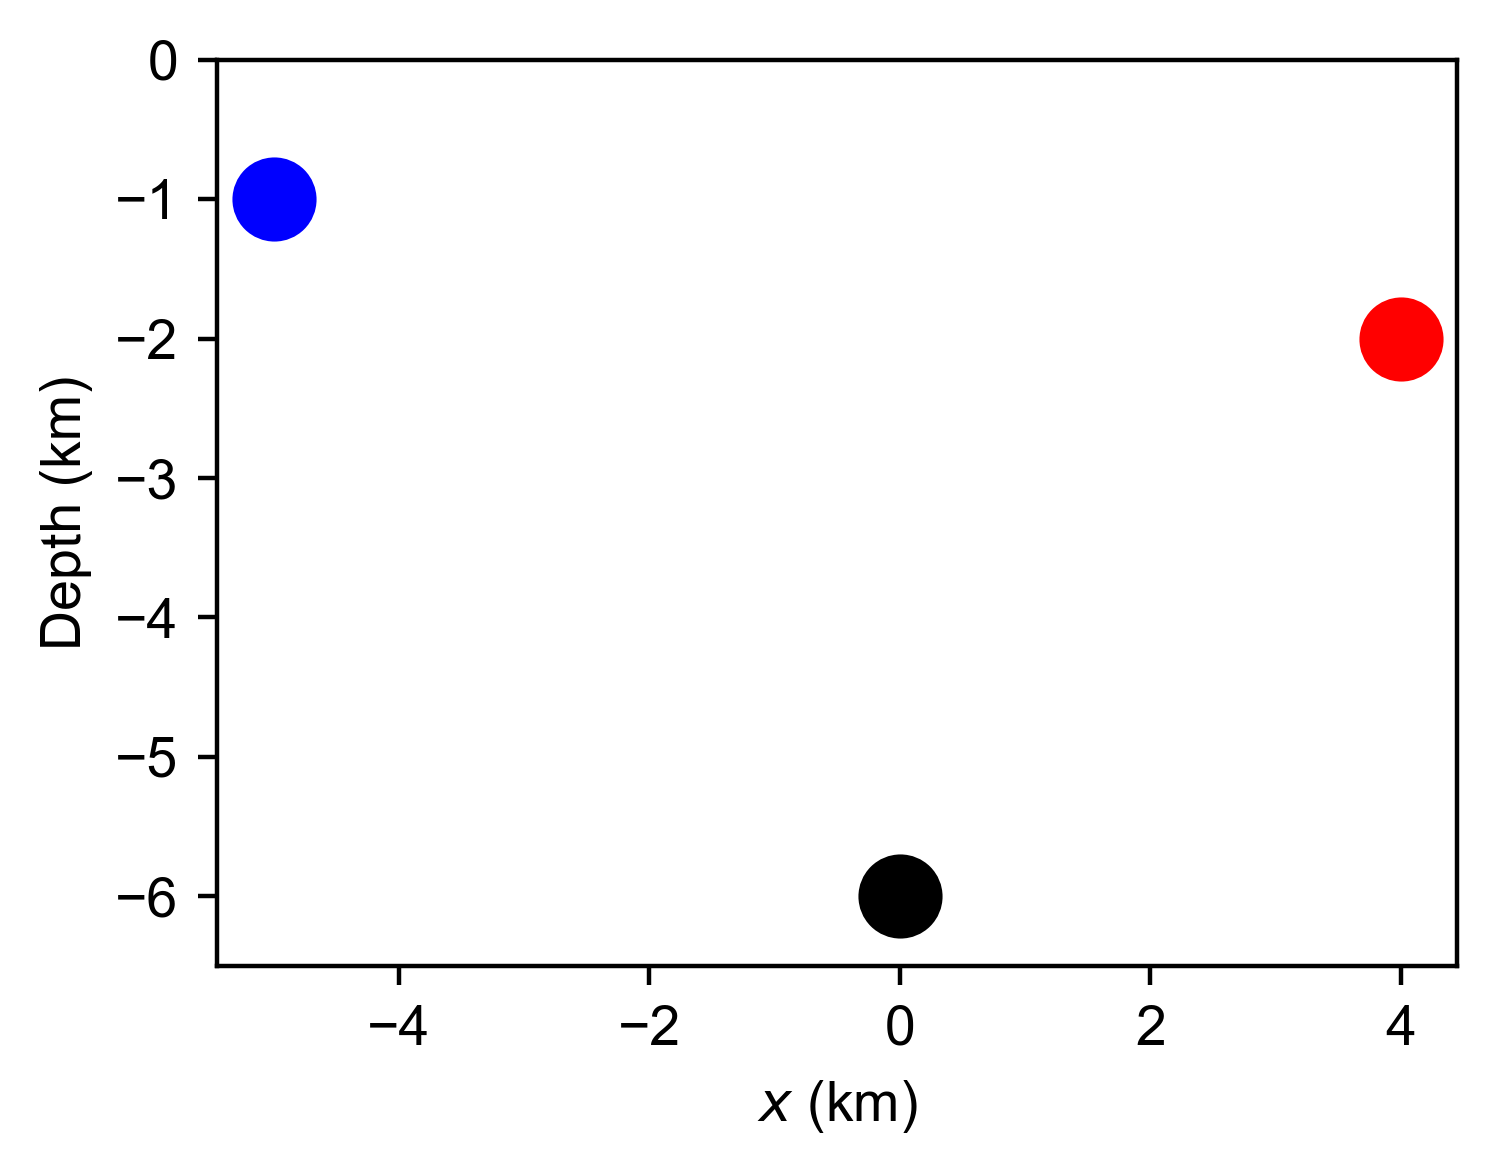

In [ ]:
plt.figure(figsize=(4,3), dpi=400)
plt.scatter(x_nodes[0]/1e3, z_nodes[0]/1e3, c='k', s=200)
plt.scatter(x_nodes[1]/1e3, z_nodes[1]/1e3, c='b', s=200)
plt.scatter(x_nodes[2]/1e3, z_nodes[2]/1e3, c='r', s=200)
plt.ylim(-6.5, 0)
plt.xlabel("$x$ (km)")
plt.ylabel("Depth (km)")

1.0 ,  3.040816326530612e-10


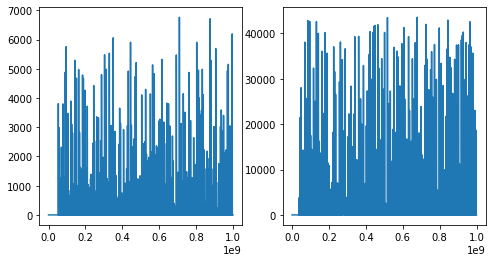

In [ ]:
# Select a specific case
i, j = 0, 25
print(mg_contrast[i,j], ", ", mg_rates[i,j])
plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.plot(t_vec, m_eruption_by_chamber[i,j][:,1])
plt.subplot(1,2,2)
plt.plot(t_vec, m_eruption_by_chamber[i,j][:,2])


Crit. overpressure ratio:  0.8148148148148148
Turnover rate (1/yr):  0.00830233469387755
Pressure history for a specific case:


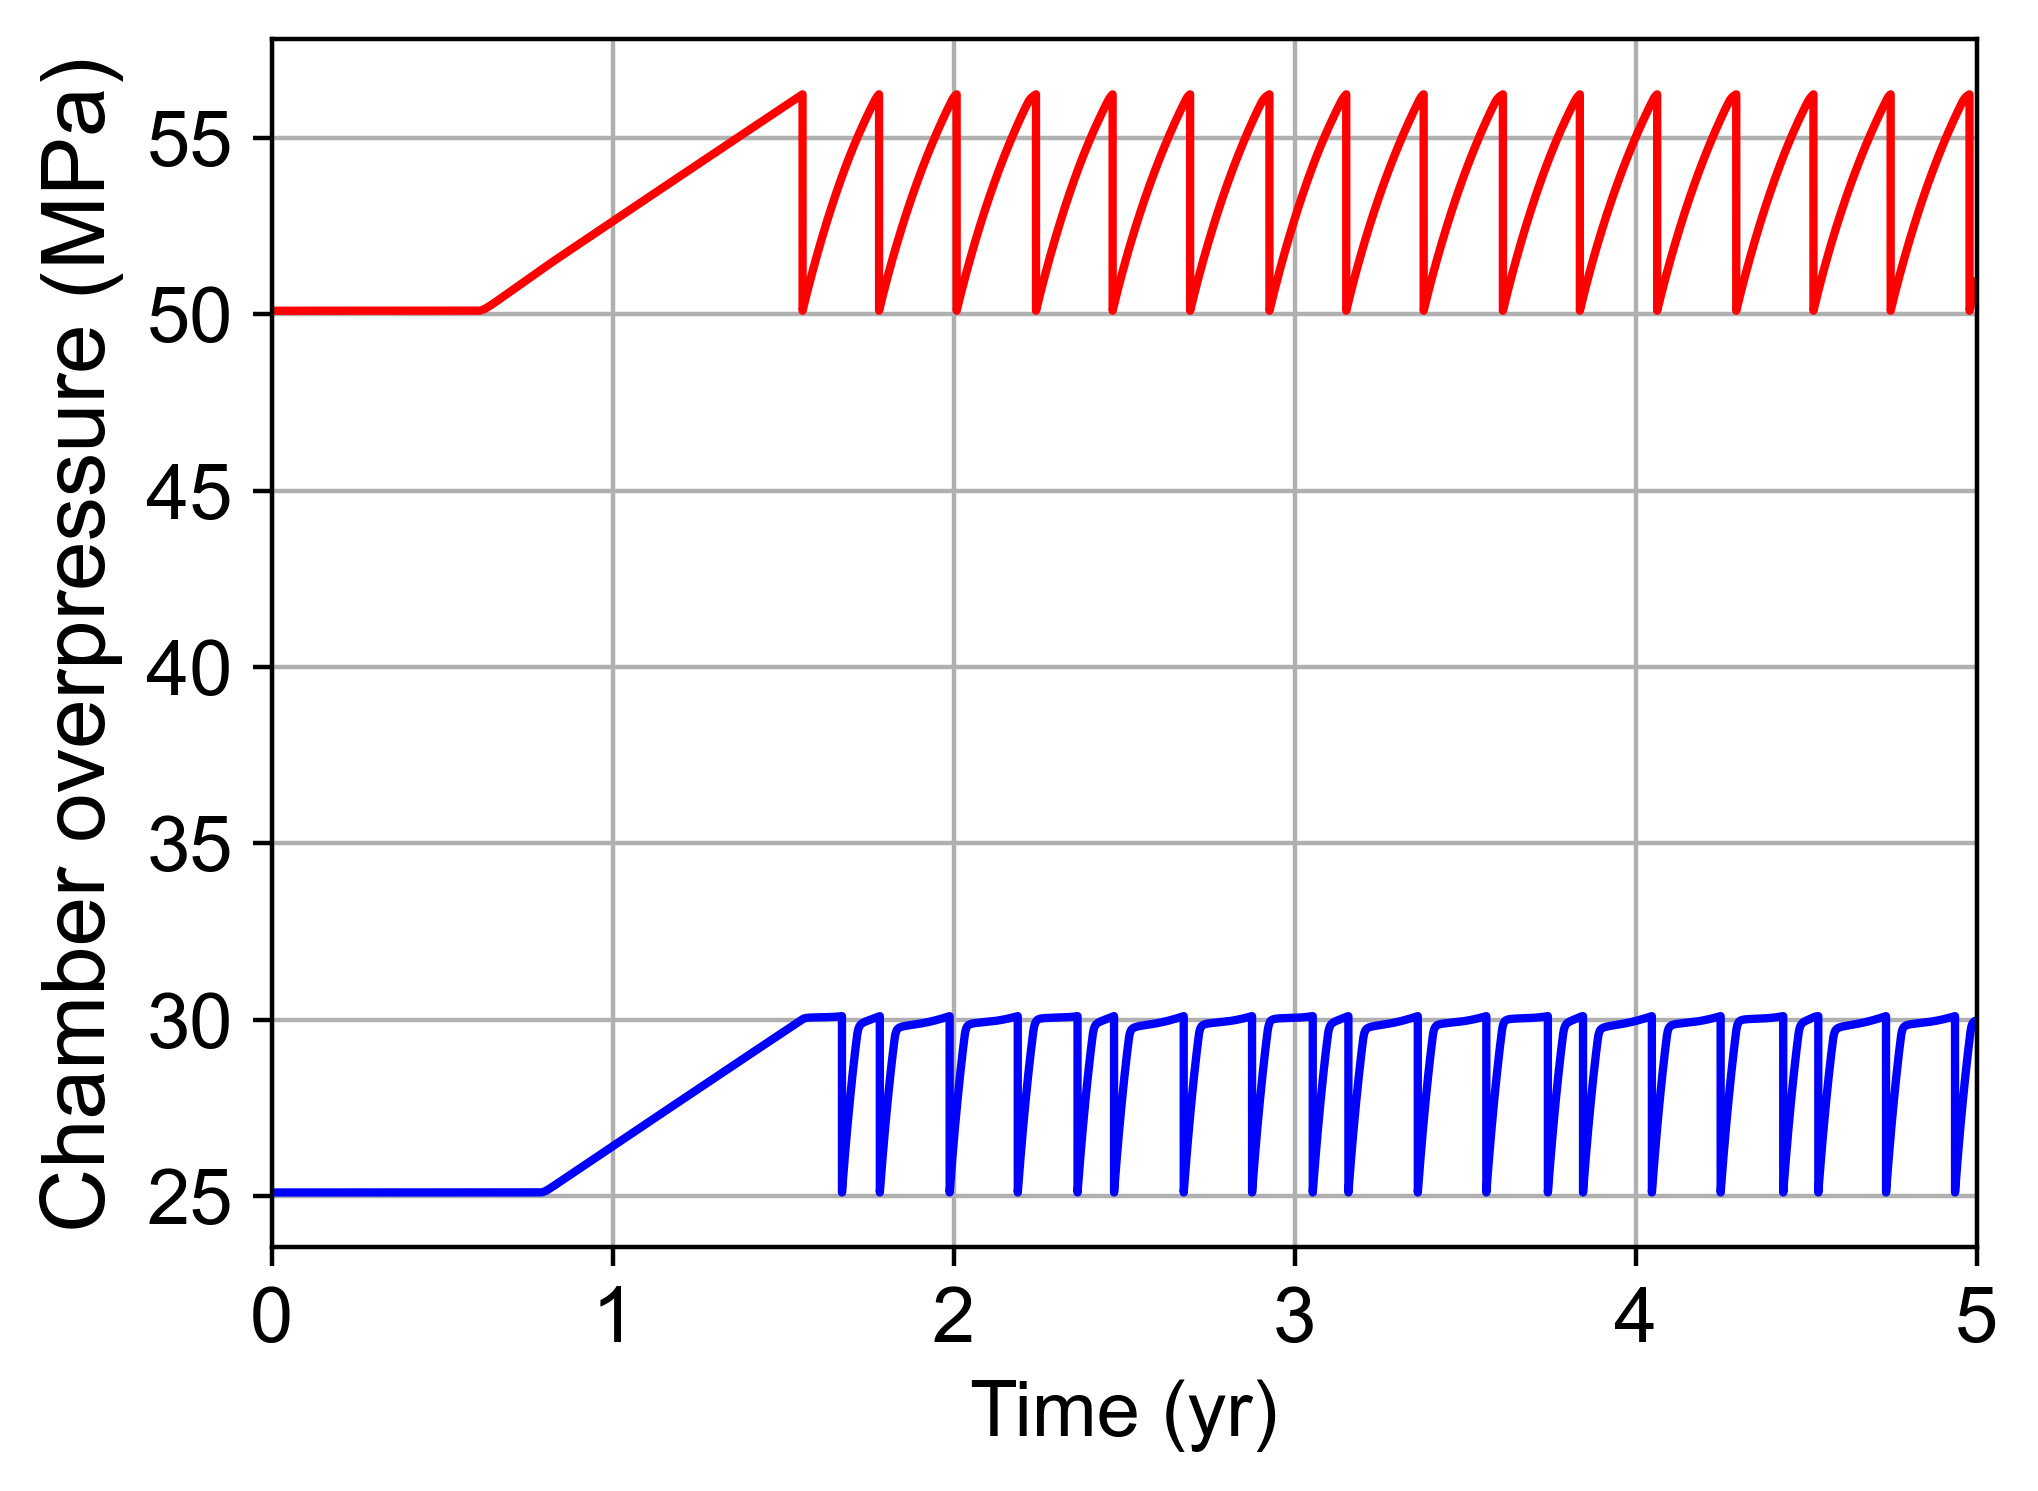

In [ ]:
# Select a specific case
i, j = 5, 20
print("Crit. overpressure ratio: ", 1/mg_contrast[i,j])
print("Turnover rate (1/yr): ", mg_rates[i,j] * 3.1536e+7)

# plt.figure(figsize=(8,4))
plt.figure(figsize=(5.5,4), dpi=400)
# plt.subplot(1,2,1)
# plt.plot(t_vec, p[i,j][:,1])
# plt.subplot(1,2,2)
plt.plot(t_vec/ 3.1536e+7, (p[i,j][:,1] - 0*p[i,j][0,1]) / 1e6, 'b', linewidth=1.5)
plt.plot(t_vec/ 3.1536e+7, (p[i,j][:,2] - 0*p[i,j][0,2]) / 1e6, 'r', linewidth=1.5)
plt.tick_params(axis="both", labelsize=14)
plt.xlabel("Time (yr)", fontsize=14)
plt.xlim(0, 5)
plt.ylabel("Chamber overpressure (MPa)", fontsize=16)
plt.grid(which="both")
print("Pressure history for a specific case:")

Crit. overpressure ratio:  0.6666666666666666
Turnover rate (1/yr):  0.00418334693877551
Pressure history for a specific case:


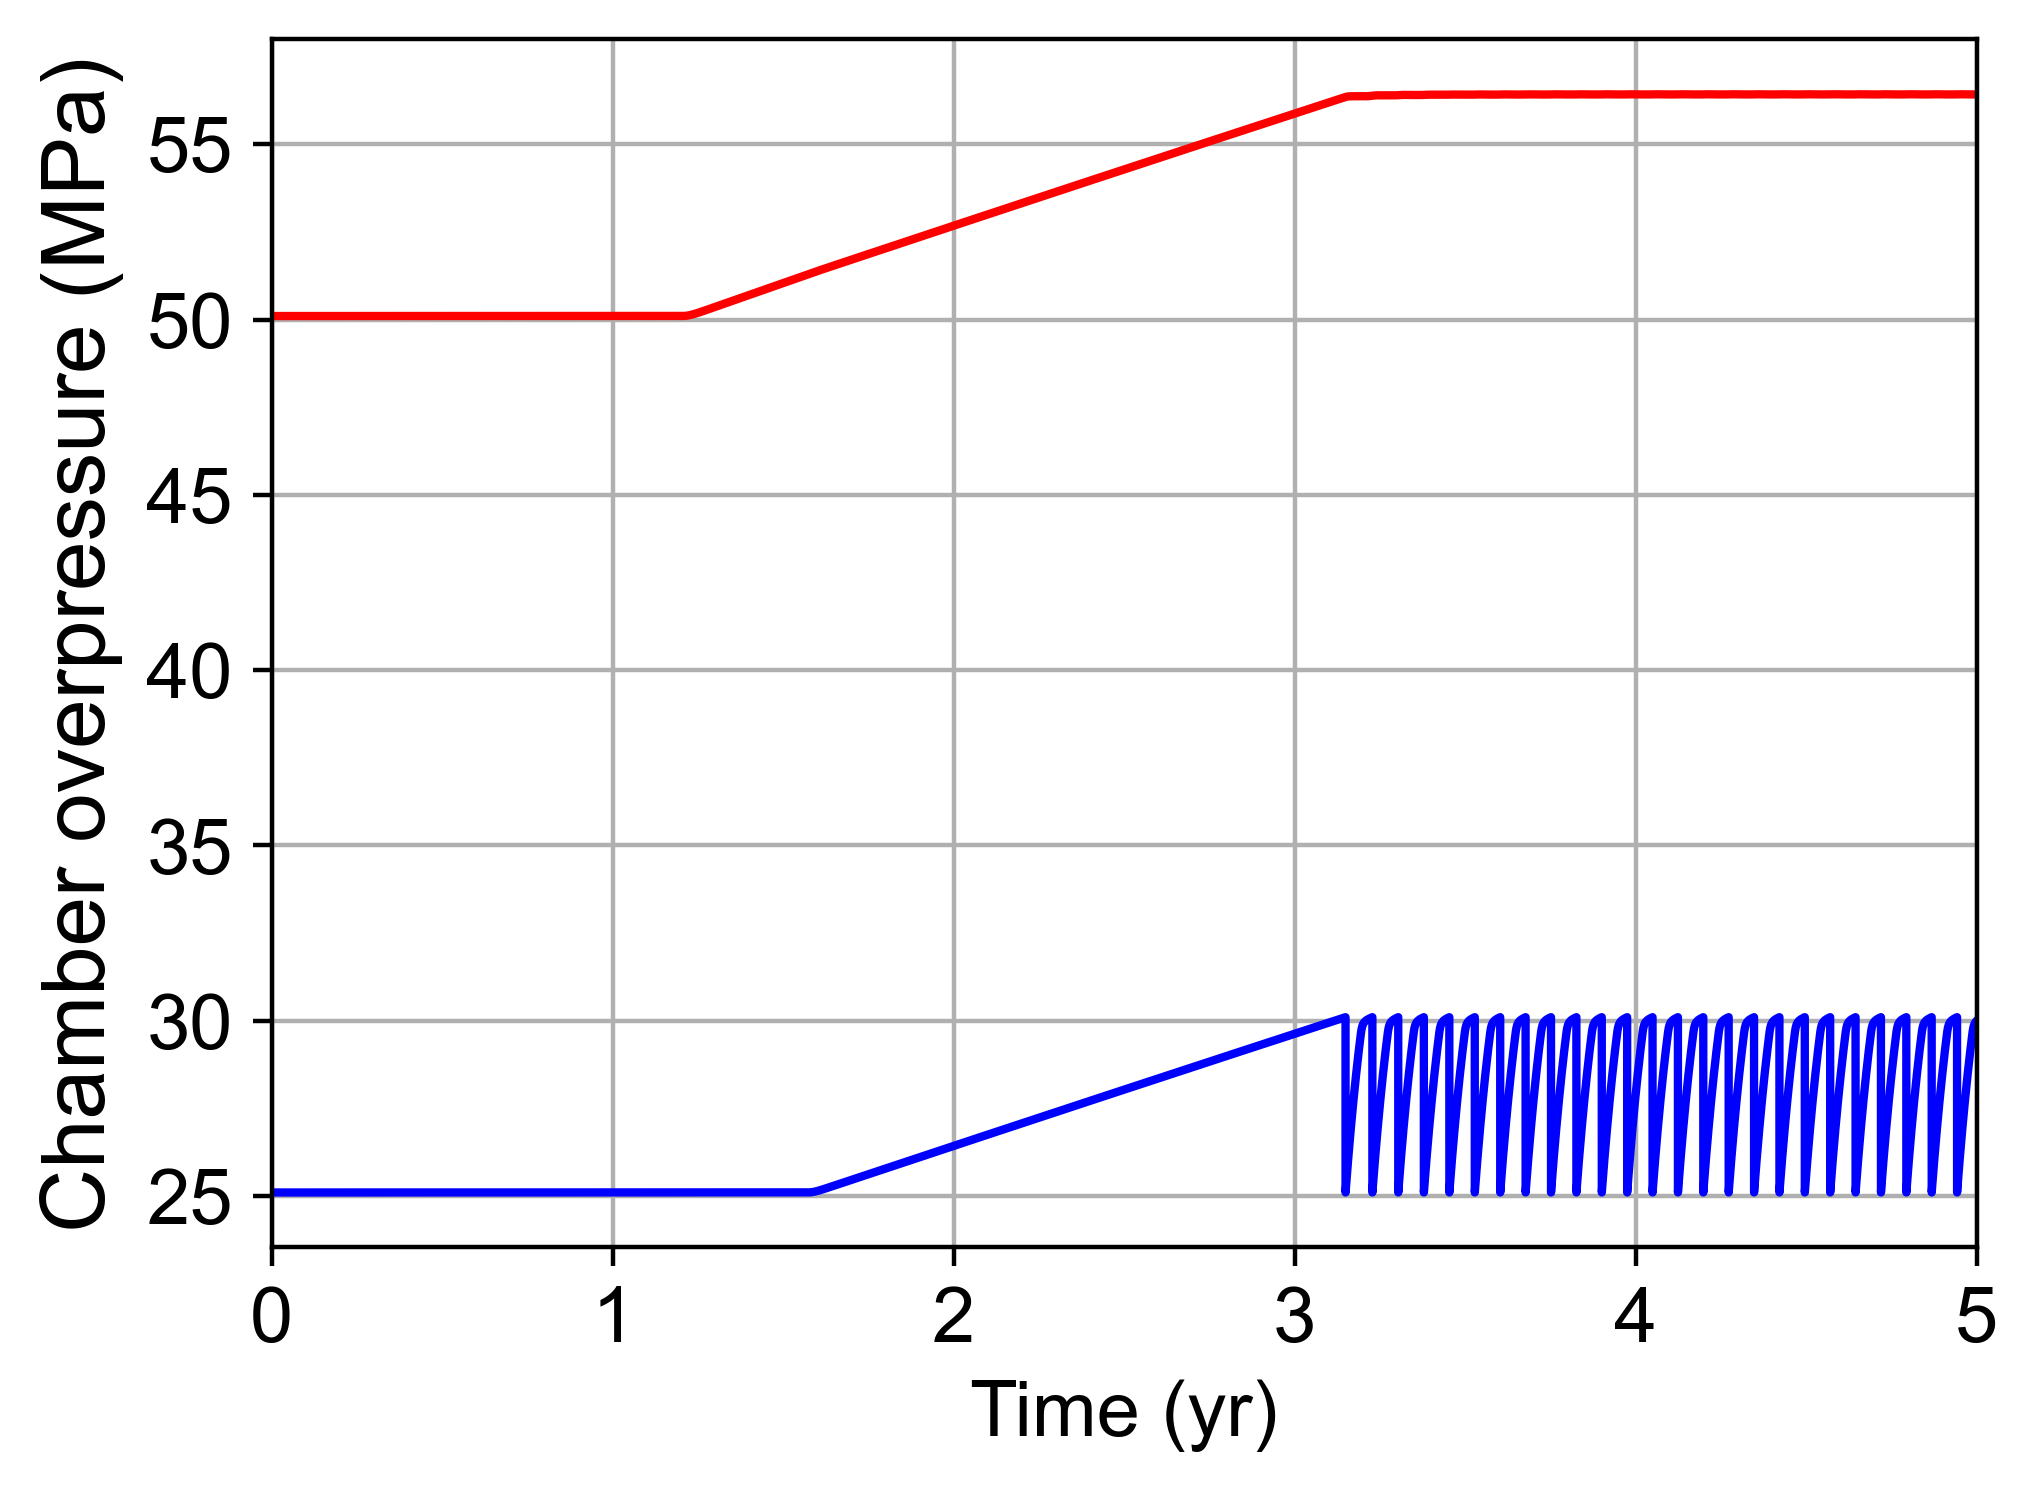

In [ ]:
# Select a specific case
i, j = -1, 4
print("Crit. overpressure ratio: ", 1/mg_contrast[i,j])
print("Turnover rate (1/yr): ", mg_rates[i,j] * 3.1536e+7)

# plt.figure(figsize=(8,4))
plt.figure(figsize=(5.5,4), dpi=400)
# plt.subplot(1,2,1)
# plt.plot(t_vec, p[i,j][:,1])
# plt.subplot(1,2,2)
plt.plot(t_vec/ 3.1536e+7, (p[i,j][:,1] - 0*p[i,j][0,1]) / 1e6, 'b', linewidth=1.5)
plt.plot(t_vec/ 3.1536e+7, (p[i,j][:,2] - 0*p[i,j][0,2]) / 1e6, 'r', linewidth=1.5)
plt.tick_params(axis="both", labelsize=14)
plt.xlabel("Time (yr)", fontsize=14)
plt.xlim(0, 5)
plt.ylabel("Chamber overpressure (MPa)", fontsize=16)
plt.grid(which="both")
print("Pressure history for a specific case:")

In [ ]:
m_eruption_by_chamber[i,j][:,1].max()

163426.55770977217

In [ ]:
def eruption_events(track):
  set_point = track[0] + 2.5e6
  w = track - set_point
  (w[1:] * w[:-1]) < 0
  # Compute boolean mask for zero-crossings of w with negative slope
  down_crossings = ((w[1:] * w[:-1]) < 0) & (w[1:] - w[:-1] < 0)
  t_centered = 0.5 * (t_vec[1:] + t_vec[:-1])
  indices_down_crossing = np.where(down_crossings)[0]
  
  if len(indices_down_crossing) < 2:
    freq = 0
  else:
    freq = scipy.stats.linregress(t_centered[down_crossings],
                                  np.arange(len(indices_down_crossing))).slope

  # Return times of crossings and indices where crossing happened (shifted by 1/2)
  return t_centered[down_crossings], indices_down_crossing, freq

avg_erupt_freq = np.zeros((*p.shape[0:2], p.shape[3],))

for i in range(p.shape[0]):
  for j in range(p.shape[1]):
    for k in range(p.shape[3]): # Each chamber
      avg_erupt_freq[i,j,k] = eruption_events(p[i,j][:,k])[2]

In [ ]:
plt.subplots(figsize=(8.5,10))

plt.subplot(2,2,1)
plt.contourf(mg_contrast, (mg_rates), eruption_partition[:,:,1],
  levels=np.linspace(0, 1, 50), cmap=matplotlib.pyplot.cm.seismic)
plt.xlabel("Eruption threshold ratio")
# plt.ylabel("Mass turnover rate: lowest node (1/s)")
plt.ylabel("Mass turnover rate (1/s)")
plt.colorbar(label="Erupted mass proportion", location="bottom",
             ticks=[0, 0.5, 1.0])

plt.subplot(2,2,2)
plt.contourf(mg_contrast, mg_rates, throughput_efficiency.squeeze(),
             levels=100)
plt.xlabel("Eruption threshold ratio")
plt.ylabel("Mass turnover rate: lowest node (1/s)")
plt.colorbar(label="Mass throughput ratio", location="bottom",
             ticks = np.linspace(0, 0.075, 4))

plt.subplot(2,2,3)
plt.contourf(mg_contrast, mg_rates, avg_erupt_freq[:,:,1], levels=100,
  cmap=matplotlib.pyplot.cm.Blues)
plt.xlabel("Eruption threshold ratio")
plt.ylabel("Mass turnover rate: lowest node (1/s)")
plt.colorbar(label="Avg. eruption frequency ($\mathrm{s}^{-1}$)",
             location="bottom",
            #  ticks = np.linspace(0, 0.075, 4)
             )

plt.subplot(2,2,4)
plt.contourf(mg_contrast, mg_rates, avg_erupt_freq[:,:,2], levels=100,
  cmap=matplotlib.pyplot.cm.Blues)
plt.xlabel("Eruption threshold ratio")
plt.ylabel("Mass turnover rate: lowest node (1/s)")
plt.colorbar(label="Avg. eruption frequency ($\mathrm{s}^{-1}$)",
             location="bottom",
            #  ticks = np.linspace(0, 0.075, 4)
             )

plt.tight_layout()

print("Plots of eruption rates by chamber: ")

NameError: name 'plt' is not defined

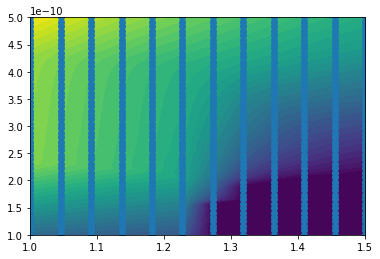

In [ ]:
plt.contourf(mg_contrast, mg_rates, avg_erupt_freq[:,:,2], levels=40)
plt.scatter(mg_contrast.ravel(), mg_rates.ravel())

In [ ]:
# Stack plot along 1.5

i, j = 49, 4
print(mg_contrast[i,j], ", ", mg_rates[i,j])
plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.plot(t_vec, p[i,j][:,1])
plt.subplot(1,2,2)
plt.plot(t_vec, p[i,j][:,2])
print("Pressure history for a specific case:")

IndexError: index 49 is out of bounds for axis 0 with size 12

In [ ]:
''' Eruption peak picking '''

pick_using_p = False

if pick_using_p:
  # Take data series
  series = p[:,-1][:] / 1e6
  # Compute boolean values corresponding to sign changes
  is_peak = (np.diff(series[1:]) > 0).astype(float) * (np.diff(series[:-1]) < 0).astype(float)
  # First time data is over 99% of the max
  first_index = np.argmax(series > 0.9 * series.max())
  # Compute indices where peak is detected in data series
  peak_indices = (first_index + 1 + np.where(is_peak[first_index:])).squeeze()

  # plt.plot(t_vec[peak_indices], '.')
  # plt.xlabel("Local peak number")
  # plt.ylabel("Time of occurence (s)")
else:
  m_erupt_indices = np.where(np.diff(m_erupted_out) > 0)[0] + 1
  peak_indices = m_erupt_indices

t_peak = t_vec[peak_indices]
np.diff(t_peak)

plt.plot(t_peak[:-1] / seconds_per_year, np.diff(t_peak) / seconds_per_year, '.')
plt.xlabel("Time (years)")
plt.ylabel("Inter-eruption period (years)")
plt.title("Case II: period between eruption (positive mass erupted)")